# 04 · Model 2: K-Nearest Neighbours (distance-weighted)
**Owner:** Monty · **Family:** Instance-based · **Script:** `models/train_knn.py`

**Why this model for PathSnap?** Tests whether candidates that *look alike* in feature space (similar distance pattern, heading agreement, context) share the same label. It is a non-parametric reference point with no distributional assumptions.

**Strengths:** no training phase, naturally non-linear, simple to explain.

**Limitations:** prediction cost grows with the training set (every query searches stored points), so it was fitted on a 25% sample of observations. It needs scaling (otherwise metres dominate 0/1 flags). With distance weighting each training point is its own nearest neighbour, so training accuracy is meaningless (about 99%).

**Loss / objective:** none (lazy learner). The prediction is a distance-weighted vote of the k=25 nearest training rows in standardised feature space (Euclidean).

**Protocol (same for all 5 models, `models/common.py`):** 5-fold **GroupKFold by trip** on the 78 clean training trips (trips 54 and 33 excluded) → refit on all of them → evaluate on the 10 student_test trips (every GPS point). Primary metric: **observation-level Top-1 accuracy**. Only one fixed configuration per model: **no grid or random search** (organiser rule). Only the selected model is tuned, with Bayesian optimisation.

In [1]:
import os, sys
# run from the repository root regardless of where the notebook lives
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("repo root:", os.getcwd())
from models.train_knn import est, cfg
from models.common import run_experiment
from pathsnap.features import FEATURE_COLUMNS
print("hyperparameters:", cfg)
est

repo root: C:\Users\shrey\OneDrive\Documents\ML Hackathon\PathSnap_7_H


hyperparameters: {'n_neighbors': 25, 'weights': 'distance', 'metric': 'minkowski', 'p': 2, 'train_sample_frac': 0.25}


,steps,"[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,25
,weights,'distance'
,algorithm,'auto'
,leaf_size,30


## Train, cross-validate and evaluate

In [2]:
row, model = run_experiment("knn", "Instance-based", est, cfg, train_sample_frac=0.25)
pd.Series(row).drop("config_json")

[knn] train rows=147,016 trips=78 | test rows=131,630


[knn] CV macroF1=0.9188±0.0153 CV top1=0.8649 | test top1=0.8626 macroF1=0.9162 logloss=0.1435 cont=0.9428 | fit 0.1s, infer 1431 ms/trip


model                                   knn
family                       Instance-based
cv_macro_f1_mean                   0.918784
cv_macro_f1_std                    0.015308
cv_top1_mean                       0.864897
cv_top1_std                        0.031998
cv_logloss                           0.1572
train_top1                         0.990819
train_macro_f1                          1.0
test_top1                           0.86263
test_macro_f1                      0.916201
test_precision                     0.867734
test_recall                        0.845389
test_logloss                       0.143457
test_cand_miss_rate                0.002818
test_route_continuity_clf           0.94277
train_time_s                           0.06
infer_ms_per_trip                   1430.83
train_rows                           147016
seed                                     42
dtype: object

In [3]:
log = json.load(open("results/model_runs/knn.json"))
folds = pd.DataFrame(log["folds"]); display(folds.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
folds.plot(x="fold", y=["top1_accuracy", "macro_f1"], marker="o", ax=ax[0]); ax[0].set_title("Per-fold CV scores"); ax[0].set_ylim(0.75, 1)
bars = pd.Series({"train (fit data)": row["train_top1"], "CV (mean)": row["cv_top1_mean"], "student_test": row["test_top1"]})
bars.plot.bar(ax=ax[1], color=["C2", "C0", "C1"]); ax[1].set_ylim(0.75, 1); ax[1].set_title("Top-1: train vs CV vs test (over/underfitting)")
for i, v in enumerate(bars): ax[1].text(i, v + .005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

,macro_f1,precision,recall,logloss,top1_accuracy,candidate_miss_rate,fold,fit_s
0,0.9187,0.8839,0.8448,0.1816,0.8678,0.0024,0,0.04
1,0.9207,0.8769,0.8480,0.1268,0.8758,0.0056,1,0.05
2,0.9312,0.8969,0.8683,0.1276,0.8879,0.0050,2,0.05
3,0.8932,0.8424,0.7883,0.1796,0.8093,0.0206,3,0.05
4,0.9301,0.8877,0.8851,0.1704,0.8837,0.0127,4,0.05


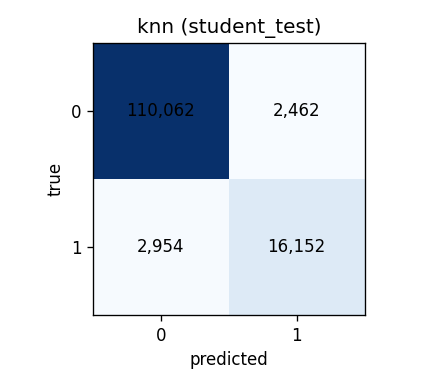

In [4]:
from IPython.display import Image
Image("results/plots/confusion_knn.png")

## Inference cost vs the other models

In [5]:
comp = pd.read_csv("results/model_comparison.csv")
comp = comp[comp.model.isin(["logreg", "knn", "random_forest", "mlp", "lightgbm"])].set_index("model")
comp.infer_ms_per_trip.sort_values().plot.barh(logx=True, figsize=(6, 2.8), title="Inference time per trip (ms, log scale)"); plt.tight_layout(); plt.show()

In [6]:
r = row
gap = r["train_top1"] - r["cv_top1_mean"]
verdict = "overfitting (large train-CV gap)" if gap > 0.05 else ("mild overfitting" if gap > 0.02 else "no overfitting (train ≈ CV; if anything, high bias)")
print(f"""Student-test results  : Top-1 {r['test_top1']:.4f} | macro F1 {r['test_macro_f1']:.4f} | precision {r['test_precision']:.4f} | recall {r['test_recall']:.4f} | log loss {r['test_logloss']:.4f}
Route continuity (classifier-only argmax): {r['test_route_continuity_clf']:.4f}
CV Top-1 {r['cv_top1_mean']:.4f} ± {r['cv_top1_std']:.4f} | CV macro F1 {r['cv_macro_f1_mean']:.4f} ± {r['cv_macro_f1_std']:.4f}
Train Top-1 {r['train_top1']:.4f} -> train-CV gap {gap:+.4f}: {verdict}
Fit time {r['train_time_s']:.1f} s | inference {r['infer_ms_per_trip']:.0f} ms per trip""")

Student-test results  : Top-1 0.8626 | macro F1 0.9162 | precision 0.8677 | recall 0.8454 | log loss 0.1435
Route continuity (classifier-only argmax): 0.9428
CV Top-1 0.8649 ± 0.0320 | CV macro F1 0.9188 ± 0.0153
Train Top-1 0.9908 -> train-CV gap +0.1259: overfitting (large train-CV gap)
Fit time 0.1 s | inference 1431 ms per trip
